<a href="https://colab.research.google.com/github/WinnieAmong/Applied_Datascience_Practice/blob/main/Copy_of_NLP_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import spacy

# Load model

nlp = spacy.load("en_core_web_sm")

text =  "NLP powers search engines."
doc = nlp(text)


# Token inspection

for token in doc:
    print(token.text,  token.pos_, token.lemma_)

NLP PROPN NLP
powers NOUN power
search NOUN search
engines NOUN engine
. PUNCT .


In [ ]:
! spacy download en_core_web_trf

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.4/457.4 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.9/237.9 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 83.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_trf')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy
nlp = spacy.load("en_core_web_trf")  # Transformer model
doc = nlp("Elon Must founded OpenAI in San Francisco.")
for ent in doc.ents:
    print(f"{ent.text:<20} → {ent.label_}")

Elon Must            → PERSON
OpenAI               → ORG
San Francisco        → GPE


[link text](https://)Install dependencies
```bash
! pip install transformers datasets scikit-learn spacy torch matplotlib seaborn wordcloud
! spacy download en_core_web_sm
```
### Table of Contents
1. [Text Preprocessing Pipeline](#1)
2. [Tokenization — Three Strategies](#2)
3. [Bag-of-Words & TF-IDF](#3)
4. [Word Embeddings](#4)
5. [Transformer Architecture](#5)
6. [BERT Fine-Tuning for Sentiment Analysis](#6)
7. [Named Entity Recognition](#7)
8. [Evaluation Metrics Deep Dive](#8)


In [ ]:
! pip install transformers datasets scikit-learn spacy torch matplotlib seaborn wordcloud

In [ ]:
! spacy download en_core_web_sm
# Used for NLP and text analysis


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 72.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# ── Core imports ─────────────────────────────────────────────────────────
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from collections import Counter

# NLP
import spacy
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# Transformers
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForTokenClassification,
    pipeline,
    TrainingArguments,
    Trainer,
)
from datasets import Dataset
import torch

nlp = spacy.load('en_core_web_sm')

# Plot style
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

---
<a id='1'></a>
## 1 · Text Preprocessing Pipeline

Raw text is messy. Before feeding it to any model you need to standardise it.
Each step below removes a different type of noise:

| Step | Why it matters |
|------|----------------|
| Lowercase | `'Dog'` and `'dog'` are the same concept |
| Remove special chars | Punctuation and symbols rarely carry meaning |
| Tokenise | Split into atomic units the model can learn from |
| Remove stop words | `'the'`, `'is'`, `'a'` add noise, not signal |
| Lemmatise | `'running'` → `'run'`; reduces vocabulary size |


In [ ]:
#  preprocessing function

STOP_WORDS = spacy.lang.en.stop_words.STOP_WORDS

def preprocess(text: str, lemmatise: bool = True) -> list[str]:
    """
      Returns a list of clean tokens ready for vectorisation.
    """
    # 1. Lowercase
    text = text.lower()

    # 2. Remove URLs, mentions, HTML tags
    text = re.sub(r'http\S+|www\.\S+', '', text)     # URLs
    text = re.sub(r'<[^>]+>', '', text)              # HTML
    text = re.sub(r'@\w+', '', text)                 # mentions

    # 3. Remove non-alpha characters (keep spaces)
    text = re.sub(r'[^a-z\s]', '', text)

    # 4. Tokenise using spaCy
    doc = nlp(text)

    # 5. Remove stop words, short tokens, and optionally lemmatise
    tokens = []
    for token in doc:
        word = token.lemma_ if lemmatise else token.text
        if word not in STOP_WORDS and len(word) > 2:
            tokens.append(word)

    return tokens


# ── Run it step by step and show each stage ──────────────────────────────
raw = "The QUICK brown foxes are RUNNING over the lazy dog's fence!! 🐶 Visit https://example.com"

stages = [
    ('Raw text',          raw),
    ('Lowercase',         raw.lower()),
    ('No URLs/HTML',      re.sub(r'http\S+', '', raw.lower())),
    ('Alpha only',        re.sub(r'[^a-z\s]', '', re.sub(r'http\S+', '', raw.lower()))),
    ('Tokens (lemma)',    str(preprocess(raw))),
]

print('── Preprocessing Pipeline ─────────────────────────────────────────')
for i, (label, result) in enumerate(stages, 1):
    print(f'  Step {i}  [{label:20s}] → {result[:80]}')

── Preprocessing Pipeline ─────────────────────────────────────────
  Step 1  [Raw text            ] → The QUICK brown foxes are RUNNING over the lazy dog's fence!! 🐶 Visit https://ex
  Step 2  [Lowercase           ] → the quick brown foxes are running over the lazy dog's fence!! 🐶 visit https://ex
  Step 3  [No URLs/HTML        ] → the quick brown foxes are running over the lazy dog's fence!! 🐶 visit 
  Step 4  [Alpha only          ] → the quick brown foxes are running over the lazy dogs fence  visit 
  Step 5  [Tokens (lemma)      ] → ['quick', 'brown', 'fox', 'run', 'lazy', 'dog', 'fence', 'visit']


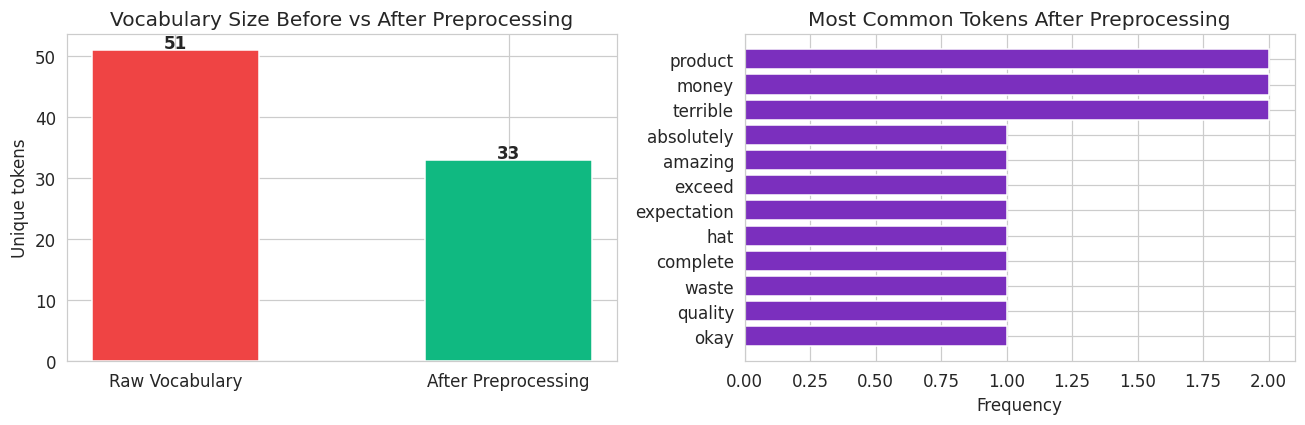

Vocabulary reduced from 51 → 33 unique tokens (35% reduction)


In [ ]:
# ── Visualise vocabulary reduction ───────────────────────────────────────

sample_reviews = [
    "The product was absolutely amazing! Really exceeded my expectations.",
    "I hated this product. Complete waste of money and terrible quality.",
    "It was okay, not great but not terrible. Shipping was fast though.",
    "Fantastic value for money! The packaging was beautiful too.",
    "Broken on arrival. Customer service was completely useless.",
    "Pretty good overall. Minor scratches but works perfectly fine.",
]

raw_vocab  = set(w.lower() for r in sample_reviews for w in r.split())
clean_vocab = set(t for r in sample_reviews for t in preprocess(r))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: vocabulary size comparison
axes[0].bar(['Raw Vocabulary', 'After Preprocessing'],
            [len(raw_vocab), len(clean_vocab)],
            color=['#EF4444', '#10B981'], edgecolor='white', width=0.5)
axes[0].set_ylabel('Unique tokens')
axes[0].set_title('Vocabulary Size Before vs After Preprocessing')
for i, v in enumerate([len(raw_vocab), len(clean_vocab)]):
    axes[0].text(i, v + 0.3, str(v), ha='center', fontweight='bold')

# Right: most common clean tokens
all_tokens = [t for r in sample_reviews for t in preprocess(r)]
token_counts = Counter(all_tokens).most_common(12)
words, counts = zip(*token_counts)
axes[1].barh(words[::-1], counts[::-1], color='#7B2FBE', edgecolor='white')
axes[1].set_xlabel('Frequency')
axes[1].set_title('Most Common Tokens After Preprocessing')

plt.tight_layout()
plt.show()

print(f'Vocabulary reduced from {len(raw_vocab)} → {len(clean_vocab)} unique tokens '
      f'({100*(1-len(clean_vocab)/len(raw_vocab)):.0f}% reduction)')

---
<a id='2'></a>
## 2 · Tokenization — Three Strategies

Tokenisation decides the vocabulary your model works with.
The right strategy depends on your task and model:

- **Word-level** — used with classical ML (TF-IDF, Word2Vec)
- **Subword (BPE / WordPiece)** — used by BERT, GPT, RoBERTa. Handles rare words gracefully.
- **Character-level** — maximum flexibility, very long sequences


In [ ]:
# ── Compare all three tokenisation strategies ─────────────────────────────

from transformers import AutoTokenizer

bert_tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
test_texts = [
    'The cats are playing in the garden.',
    'Unbelievably fantastic NLP results!',   # 'Unbelievably' tests subword
    'COVID-19 pandemic affected everyone.',  # Hyphen + numbers test
]

print(f'{"Input Text":<40}  {"Word Tokens":<8}  {"BERT Subword Tokens":<30}  {"Char Tokens"}')
print('─' * 120)

for text in test_texts:
    word_tokens = text.lower().split()
    bert_tokens = bert_tokenizer.tokenize(text)
    char_tokens = list(text.replace(' ', '_'))

    print(f'{text[:38]:<40}  {str(word_tokens)[:30]:<35}  {str(bert_tokens)[:55]:<58}  {len(char_tokens)} chars')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Input Text                                Word Tokens  BERT Subword Tokens             Char Tokens
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
The cats are playing in the garden.       ['the', 'cats', 'are', 'playin       ['the', 'cats', 'are', 'playing', 'in', 'the', 'garden'     35 chars
Unbelievably fantastic NLP results!       ['unbelievably', 'fantastic',        ['un', '##bel', '##ie', '##va', '##bly', 'fantastic', '     35 chars
COVID-19 pandemic affected everyone.      ['covid-19', 'pandemic', 'affe       ['co', '##vid', '-', '19', 'pan', '##de', '##mic', 'aff     36 chars


**Notice:** BERT splits "unbelievably" → [['un', '##bel', '##ie', '##va', '##bly'] — this is BPE/WordPiece subword tokenisation.

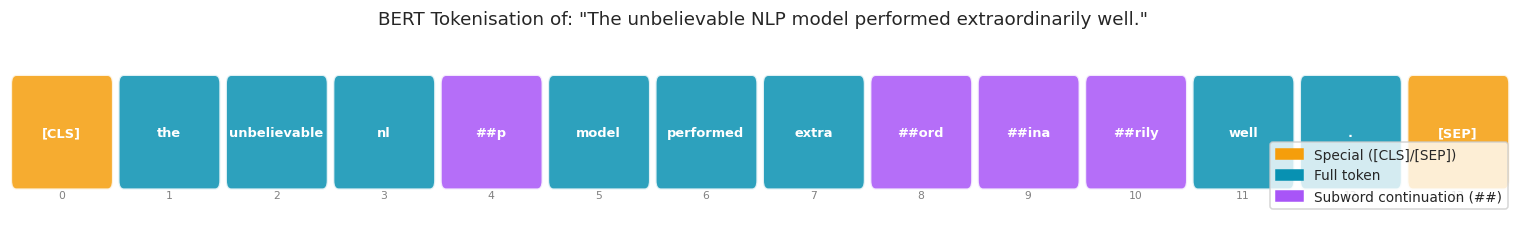

Input: 7 words  →  BERT tokens: 14 (including [CLS] and [SEP])


In [ ]:
# ── Visualise BERT tokenisation with special tokens ───────────────────────

sentence = 'The unbelievable NLP model performed extraordinarily well.'
encoded  =  (sentence, return_tensors='pt')
tokens   = bert_tokenizer.convert_ids_to_tokens(encoded['input_ids'][0])

# Colour by token type
colors = []
for t in tokens:
    if t in ('[CLS]', '[SEP]'):  colors.append('#F59E0B')   # special
    elif t.startswith('##'):     colors.append('#A855F7')   # subword continuation
    else:                        colors.append('#0891B2')   # regular token

fig, ax = plt.subplots(figsize=(14, 2.2))
ax.set_xlim(0, len(tokens))
ax.set_ylim(0, 1)
ax.axis('off')
ax.set_title(f'BERT Tokenisation of: "{sentence}"', fontsize=12, pad=10)

for i, (tok, col) in enumerate(zip(tokens, colors)):
    ax.add_patch(mpatches.FancyBboxPatch(
        (i + 0.05, 0.2), 0.85, 0.55,
        boxstyle='round,pad=0.05', fc=col, ec='white', lw=1.5, alpha=0.85
    ))
    ax.text(i + 0.47, 0.47, tok, ha='center', va='center',
            fontsize=8.5, color='white', fontweight='bold')
    ax.text(i + 0.47, 0.12, str(i), ha='center', va='center',
            fontsize=7, color='gray')

legend = [
    mpatches.Patch(color='#F59E0B', label='Special ([CLS]/[SEP])'),
    mpatches.Patch(color='#0891B2', label='Full token'),
    mpatches.Patch(color='#A855F7', label='Subword continuation (##)'),
]
ax.legend(handles=legend, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()
print(f'Input: {len(sentence.split())} words  →  BERT tokens: {len(tokens)} (including [CLS] and [SEP])')

---
<a id='3'></a>
## 3 · Bag-of-Words & TF-IDF

Classical representations that turn text into numeric vectors.
Still use as your baseline before reaching for BERT.

**Bag-of-Words (BoW):** count how many times each vocabulary word appears.

**TF-IDF:**
- **TF** (Term Frequency) = `count(t, d) / total_words(d)` — how common is this word in *this* document?
- **IDF** (Inverse Document Frequency) = `log(N / df(t))` — how rare is this word across *all* documents?
- Result: common words like *'the'* get near-zero scores; rare, meaningful words get high scores.


In [ ]:
# ── Build TF-IDF vectors and train a classifier ───────────────────────────

# Sample corpus (positive=1, negative=0)
corpus = [
    'I love this product, it is absolutely fantastic',
    'Amazing quality and great value for money',
    'The best purchase I have ever made',
    'Excellent service and fast delivery',
    'Really happy with my order, highly recommend',
    'Terrible product, complete waste of money',
    'Broken on arrival, very disappointed',
    'Awful quality and terrible customer service',
    'Never buying again, absolutely horrible',
    'Total rubbish, do not waste your money',
]
labels = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]

# Build the pipeline: TF-IDF → RandomForestClassifier
clf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=500,
        ngram_range=(1, 2),      # unigrams + bigrams
        sublinear_tf=True,       # apply log(1+tf) to reduce impact of very common terms
        min_df=1,
    )),
    ('clf', RandomForestClassifier(random_state=42)),
])

clf_pipeline.fit(corpus, labels)

# Test on new sentences
test_sentences = [
    'This is an excellent product, I love it',
    'Complete garbage and waste of money, I hate it',
    'It was okay, nothing special',
]
preds = clf_pipeline.predict(test_sentences)
probas = clf_pipeline.predict_proba(test_sentences)

print(f'{"Sentence":<45}  {"Prediction":<12}  {"Confidence"}')
print('─' * 80)
for sent, pred, prob in zip(test_sentences, preds, probas):
    label  = '✅ Positive' if pred == 1 else '❌ Negative'
    conf   = max(prob)
    print(f'{sent[:43]:<45}  {label:<12}  {conf:.1%}')

Sentence                                       Prediction    Confidence
────────────────────────────────────────────────────────────────────────────────
This is an excellent product, I love it        ✅ Positive    57.0%
Complete garbage and waste of money, I hate    ❌ Negative    61.0%
It was okay, nothing special                   ❌ Negative    51.0%


In [ ]:
# ── Build TF-IDF vectors and train a Logistic Regression classifier ─────

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Sample corpus (positive=1, negative=0)
corpus = [
    'I love this product, it is absolutely fantastic',
    'Amazing quality and great value for money',
    'The best purchase I have ever made',
    'Excellent service and fast delivery',
    'Really happy with my order, highly recommend',
    'Terrible product, complete waste of money',
    'Broken on arrival, very disappointed',
    'Awful quality and terrible customer service',
    'Never buying again, absolutely horrible',
    'Total rubbish, do not waste your money',
]

labels = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]

# Build the pipeline: TF-IDF → Logistic Regression
clf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=500,
        ngram_range=(1, 2),      # unigrams + bigrams
        sublinear_tf=True,       # reduce impact of common terms
        min_df=1,
    )),
    ('clf', LogisticRegression(
        random_state=42,
        max_iter=1000
    )),
])

# Train the model
clf_pipeline.fit(corpus, labels)

# Test on new sentences
test_sentences = [
    'This is an excellent product, I love it',
    'Complete garbage and waste of money, I hate it',
    'It was okay, nothing special',
]

# Make predictions
preds = clf_pipeline.predict(test_sentences)

# Get probabilities
probas = clf_pipeline.predict_proba(test_sentences)

# Display results
print(f'{"Sentence":<45}  {"Prediction":<12}  {"Confidence"}')
print('─' * 80)

for sent, pred, prob in zip(test_sentences, preds, probas):
    label = '✅ Positive' if pred == 1 else '❌ Negative'
    conf = max(prob)

    print(f'{sent[:43]:<45}  {label:<12}  {conf:.1%}')

Sentence                                       Prediction    Confidence
────────────────────────────────────────────────────────────────────────────────
This is an excellent product, I love it        ✅ Positive    56.5%
Complete garbage and waste of money, I hate    ❌ Negative    55.1%
It was okay, nothing special                   ✅ Positive    53.2%


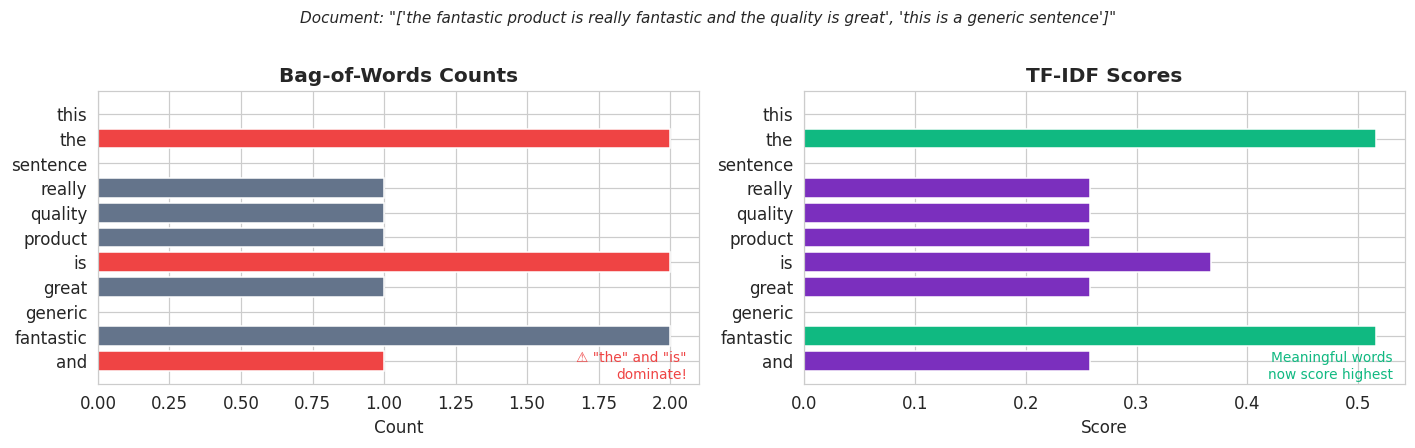

In [ ]:
# ── Visualise TF-IDF scores: BoW vs TF-IDF comparison ─────────────────────

# doc = 'the fantastic product is really fantastic and the quality is great'
doc = [
    'the fantastic product is really fantastic and the quality is great',
    'this is a generic sentence'
]

bow_vec   = CountVectorizer()
tfidf_vec = TfidfVectorizer()

bow_vec.fit(doc)
tfidf_vec.fit(doc)

bow_scores   = dict(zip(bow_vec.get_feature_names_out(),   bow_vec.transform(doc).toarray()[0]))
tfidf_scores = dict(zip(tfidf_vec.get_feature_names_out(), tfidf_vec.transform(doc).toarray()[0]))

words = sorted(bow_scores.keys())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

b_vals = [bow_scores[w]   for w in words]
t_vals = [tfidf_scores[w] for w in words]

bar_colors_bow   = ['#EF4444' if w in ('the', 'is', 'and') else '#64748B' for w in words]
bar_colors_tfidf = ['#10B981' if v == max(t_vals) else '#7B2FBE' for v in t_vals]

ax1.barh(words, b_vals, color=bar_colors_bow, edgecolor='white')
ax1.set_title('Bag-of-Words Counts', fontweight='bold')
ax1.set_xlabel('Count')
ax1.text(0.98, 0.02, '⚠ "the" and "is"\ndominate!',
         transform=ax1.transAxes, ha='right', color='#EF4444', fontsize=9)

ax2.barh(words, t_vals, color=bar_colors_tfidf, edgecolor='white')
ax2.set_title('TF-IDF Scores', fontweight='bold')
ax2.set_xlabel('Score')
ax2.text(0.98, 0.02, 'Meaningful words\nnow score highest',
         transform=ax2.transAxes, ha='right', color='#10B981', fontsize=9)

plt.suptitle(f'Document: "{doc}"', fontsize=10, style='italic', y=1.01)
plt.tight_layout()
plt.show()

---
<a id='4'></a>
## 4 · Word Embeddings

Instead of sparse counts, embeddings map each word to a **dense vector** of ~100–300 numbers.
Words with similar meaning end up in similar positions in this vector space.

The famous analogy: **king − man + woman ≈ queen**

We'll use a pre-trained model from 🤗 Transformers to extract contextual embeddings,
then project them into 2D to visualise the semantic space.


In [ ]:
! pip install sentencepiece

In [ ]:
# ── Extract contextual embeddings with a small BERT model ─────────────────

from transformers import AutoModel, AutoTokenizer
from sklearn.decomposition import PCA

model_name = 'bert-base-uncased'   # ~17MB — swap for 'bert-base-uncased' for better quality
tokenizer  = AutoTokenizer.from_pretrained(model_name)
model      = AutoModel.from_pretrained(model_name)
model.eval()

def get_embedding(text: str) -> np.ndarray:
    """Return the mean-pooled sentence embedding (CLS-free approach)."""
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=64)
    with torch.no_grad():
        outputs = model(**inputs)
    # Mean pool over token dimension, squeeze batch
    return outputs.last_hidden_state.mean(dim=1).squeeze().numpy()


# Words grouped by semantic cluster
clusters = {
    'Royalty':  ['king', 'queen', 'prince', 'princess', 'throne'],
    'Animals':  ['cat', 'kitten', 'dog', 'puppy', 'horse'],
    'Technology': ['code', 'data', 'model', 'algorithm', 'neural'],
    'Food':     ['pizza', 'sushi', 'burger', 'pasta', 'taco'],
}
cluster_colors = {'Royalty':'#A855F7', 'Animals':'#06B6D4', 'Technology':'#F59E0B', 'Food':'#10B981'}

all_words = [w for words in clusters.values() for w in words]
embeddings = np.stack([get_embedding(w) for w in all_words])

# Reduce to 2D
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(embeddings)
print(f'Embeddings: {embeddings.shape}  →  PCA 2D: {coords.shape}')
print(f'Variance explained by 2 components: {pca.explained_variance_ratio_.sum():.1%}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embeddings: (20, 768)  →  PCA 2D: (20, 2)
Variance explained by 2 components: 39.0%


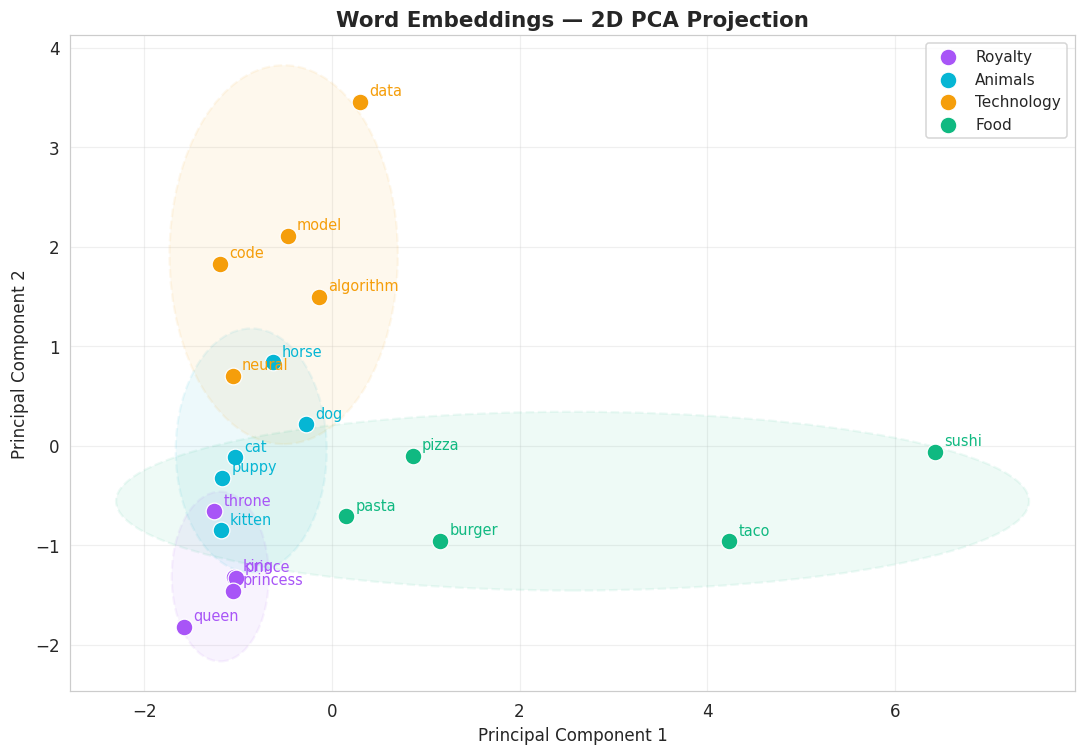

In [ ]:
# ── Plot semantic vector space ─────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 7))

idx = 0
for cluster_name, words in clusters.items():
    color = cluster_colors[cluster_name]
    xs = coords[idx:idx+len(words), 0]
    ys = coords[idx:idx+len(words), 1]

    ax.scatter(xs, ys, c=color, s=120, zorder=3, label=cluster_name, edgecolors='white', linewidths=0.8)
    for x, y, w in zip(xs, ys, words):
        ax.annotate(w, (x, y), textcoords='offset points', xytext=(6, 4), fontsize=9.5, color=color)

    # Draw a convex hull / ellipse around each cluster
    from matplotlib.patches import Ellipse
    mean_x, mean_y = xs.mean(), ys.mean()
    std_x,  std_y  = xs.std()+0.05,  ys.std()+0.05
    ellipse = Ellipse((mean_x, mean_y), width=std_x*4, height=std_y*4,
                      fc=color, alpha=0.07, ec=color, lw=1.5, linestyle='--')
    ax.add_patch(ellipse)
    idx += len(words)

ax.set_title('Word Embeddings — 2D PCA Projection', fontsize=14, fontweight='bold')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Notice how words from the same semantic cluster group together!

<a id='5'></a>
## 5 · Transformer Architecture — Attention Intuition

The key idea of Transformers is **self-attention**: each token can look at every other token
to build a rich, context-aware representation.

The formula is:
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

- **Q (Query):** what the current token is looking for
- **K (Key):** what each token advertises it contains
- **V (Value):** the actual content to mix in if attention is high

We'll visualise real attention weights from a pre-trained BERT model.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


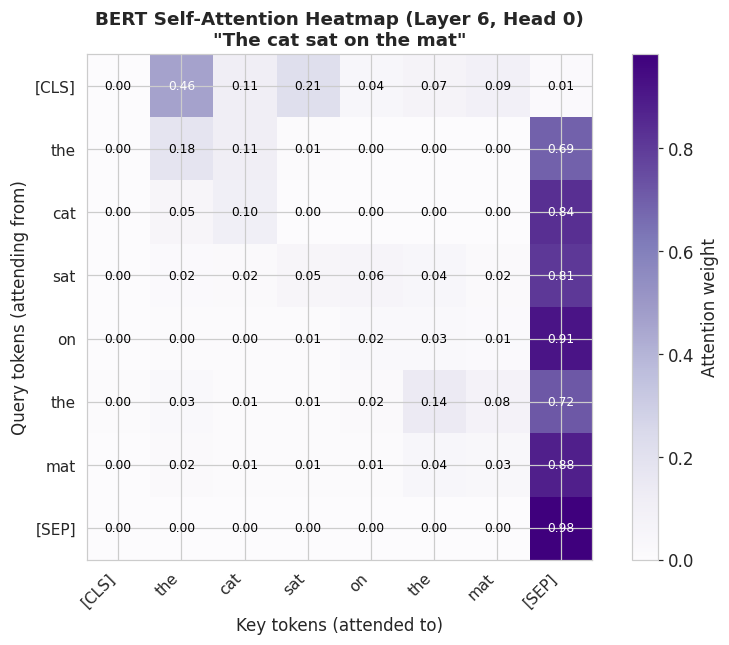

Each row shows what that token attends to. Higher = more attention.
Notice [CLS] often attends broadly — it aggregates sentence meaning.


In [ ]:
# ── Extract and visualise BERT attention weights ───────────────────────────

from transformers import AutoModel, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
model     = AutoModel.from_pretrained('bert-base-uncased', output_attentions=True)
model.eval()

sentence  = 'The cat sat on the mat'
inputs    = tokenizer(sentence, return_tensors='pt')
tokens    = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

with torch.no_grad():
    outputs = model(**inputs)

# outputs.attentions: tuple of (num_layers,) each [batch, heads, seq, seq]
# Use layer 6, head 0 as an illustrative example
attn_layer6_head0 = outputs.attentions[6][0, 0].numpy()   # [seq, seq]

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(attn_layer6_head0, cmap='Purples', vmin=0)

ax.set_xticks(range(len(tokens)))
ax.set_yticks(range(len(tokens)))
ax.set_xticklabels(tokens, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(tokens, fontsize=10)

# Annotate each cell
for i in range(len(tokens)):
    for j in range(len(tokens)):
        val = attn_layer6_head0[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=8, color='white' if val > 0.3 else 'black')

plt.colorbar(im, ax=ax, label='Attention weight')
ax.set_title(f'BERT Self-Attention Heatmap (Layer 6, Head 0)\n"{sentence}"',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Key tokens (attended to)')
ax.set_ylabel('Query tokens (attending from)')
plt.tight_layout()
plt.show()

print('Each row shows what that token attends to. Higher = more attention.')
print('Notice [CLS] often attends broadly — it aggregates sentence meaning.')

---
<a id='6'></a>
## 6 · Fine-Tuning BERT for Sentiment Analysis

Fine-tuning is the standard approach:
1. Load a pre-trained BERT checkpoint (the model already 'knows' language)
2. Add a small classification head on top
3. Train on your labelled data for just 3–5 epochs

We'll use the 🤗 `Trainer` API which handles the training loop for us.

> **Note:** This uses `distilbert-base-uncased` (~250MB) for speed. Swap for `bert-base-uncased` for better accuracy.


In [ ]:
# ── Fine-tune DistilBERT on a sentiment dataset ───────────────────────────

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from datasets import Dataset, load_dataset
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

MODEL_NAME = 'distilbert-base-uncased'
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

# ── Option A: use a small synthetic dataset (no download needed) ──────────
# ── Option B: replace with IMDb: load_dataset('imdb') ─────────────────────

pos_texts = [
    'Absolutely loved this product, it exceeded all expectations.',
    'Best purchase of the year. Highly recommend to everyone.',
    'Outstanding quality and excellent value for money.',
    'Fantastic service and the delivery was really fast.',
    'Works perfectly, exactly as described. Very happy.',
    'The quality is superb and packaging was beautiful.',
    'Really impressed with this. Will definitely buy again.',
    'Five stars without hesitation. Amazing product.',
]
neg_texts = [
    'Total waste of money. Broke after one day.',
    'Arrived completely broken. Very disappointed.',
    'Terrible customer service and awful quality.',
    'Never buying from this company again. Horrible.',
    'The product looks nothing like the photos.',
    'Complete rubbish. Do not waste your money on this.',
    'Shocking quality. Fell apart immediately.',
    'Absolute garbage. Would give zero stars if I could.',
]

texts  = pos_texts + neg_texts
labels = [1]*len(pos_texts) + [0]*len(neg_texts)

# Tokenise
def tokenize_fn(batch):
    return tokenizer(batch['text'], truncation=True, max_length=128)

raw_ds = Dataset.from_dict({'text': texts, 'label': labels})
ds     = raw_ds.map(tokenize_fn, batched=True).train_test_split(test_size=0.25, seed=42)

# Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    id2label={0: 'NEGATIVE', 1: 'POSITIVE'},
    label2id={'NEGATIVE': 0, 'POSITIVE': 1},
)

# Metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1':       f1_score(labels, preds, average='binary'),
    }

# Training config — tuned for small dataset
args = TrainingArguments(
    output_dir          = '/tmp/nlp_sentiment',
    num_train_epochs    = 5,
    per_device_train_batch_size = 4,
    per_device_eval_batch_size  = 4,
    learning_rate       = 2e-5,      # Key hyperparameter for fine-tuning
    weight_decay         = 0.01,
    eval_strategy       = 'epoch',
    save_strategy       = 'epoch',
    load_best_model_at_end = True,
    metric_for_best_model  = 'f1',
    # logging_dir         = '/tmp/nlp_logs',
    report_to           = 'none',     # Disable WandB/TensorBoard for this demo
)

trainer = Trainer(
    model           = model,
    args            = args,
    train_dataset   = ds['train'],
    eval_dataset    = ds['test'],
    data_collator   = DataCollatorWithPadding(tokenizer),
    compute_metrics = compute_metrics,
)

print('Starting fine-tuning...')
trainer.train()
results = trainer.evaluate()
print(f"\n✅  Eval accuracy: {results['eval_accuracy']:.2%}   F1: {results['eval_f1']:.3f}")


Map:   0%|          | 0/16 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting fine-tuning...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.746170,5,0.250000,0.400000



✅  Eval accuracy: 25.00%   F1: 0.400


In [ ]:
# ── Run inference on new sentences ────────────────────────────────────────

sentiment_pipeline = pipeline('text-classification', model=model, tokenizer=tokenizer)

test_reviews = [
    'This product is absolutely incredible, best thing I have bought all year!',
    'Worst experience ever. Terrible product and zero customer support.',
    'Decent product but nothing special. Does what it says on the box.',
    'Fast delivery, good quality. Would buy again.',
    'Completely broken when it arrived. Very disappointing.',
]

print(f'{"Review":<62}  {"Label":<12}  Score')
print('─' * 90)
for review in test_reviews:
    result = sentiment_pipeline(review)[0]
    emoji  = '😊' if result['label'] == 'POSITIVE' else '😞'
    print(f'{review[:60]:<62}  {emoji} {result["label"]:<10}  {result["score"]:.3f}')

Review                                                          Label         Score
──────────────────────────────────────────────────────────────────────────────────────────
This product is absolutely incredible, best thing I have bou    😊 POSITIVE    0.554
Worst experience ever. Terrible product and zero customer su    😊 POSITIVE    0.552
Decent product but nothing special. Does what it says on the    😊 POSITIVE    0.558
Fast delivery, good quality. Would buy again.                   😊 POSITIVE    0.547
Completely broken when it arrived. Very disappointing.          😊 POSITIVE    0.550


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


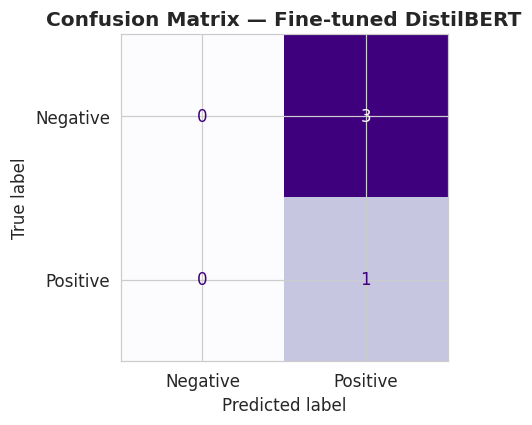

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         3
    Positive       0.25      1.00      0.40         1

    accuracy                           0.25         4
   macro avg       0.12      0.50      0.20         4
weighted avg       0.06      0.25      0.10         4



In [ ]:
# ── Confusion matrix visualisation ────────────────────────────────────────

preds_output = trainer.predict(ds['test'])
y_pred = np.argmax(preds_output.predictions, axis=1)
y_true = np.array(ds['test']['label'])

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(ax=ax, cmap='Purples', colorbar=False)
ax.set_title('Confusion Matrix — Fine-tuned DistilBERT', fontweight='bold')
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=['Negative', 'Positive']))

---
<a id='7'></a>
## 7 · Named Entity Recognition (NER)

NER identifies and classifies *spans* of text into categories like PERSON, ORG, DATE, GPE.

We'll use:
1. **spaCy** — rule + ML hybrid, great for production speed
2. **Transformers `pipeline`** — transformer-based NER, higher accuracy


In [ ]:
# ── spaCy NER with span visualisation ─────────────────────────────────────

from spacy import displacy

nlp_ner = spacy.load('en_core_web_sm')

article = (
    'On 15 January 2026, the founder of NileStream, a logistics startup, '
    'announced that they secured UGX 800 million in seed funding from '
    'the Rwenzori Venture Group, based in Mbarara, Western Uganda. '
    'The deal valued the Kampala-based tech hub at over 5 billion UGX.'
)

doc = nlp_ner(article)

# Display inline in notebook (renders HTML)
displacy.render(doc, style='ent', jupyter=True)

# Also print structured output
print('\nStructured NER output:')
print(f'{"Entity":<25}  {"Label":<10}  {"Start":<6}  End')
print('─' * 55)
for ent in doc.ents:
    print(f'{ent.text:<25}  {ent.label_:<10}  {ent.start_char:<6}  {ent.end_char}')


Structured NER output:
Entity                     Label       Start   End
───────────────────────────────────────────────────────
15 January 2026            DATE        3       18
NileStream                 ORG         35      45
800 million                CARDINAL    100     111
the Rwenzori Venture Group  ORG         133     159
Mbarara                    GPE         170     177
Western Uganda             LOC         179     193
Kampala                    GPE         215     222
over 5 billion UGX         MONEY       241     259


config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

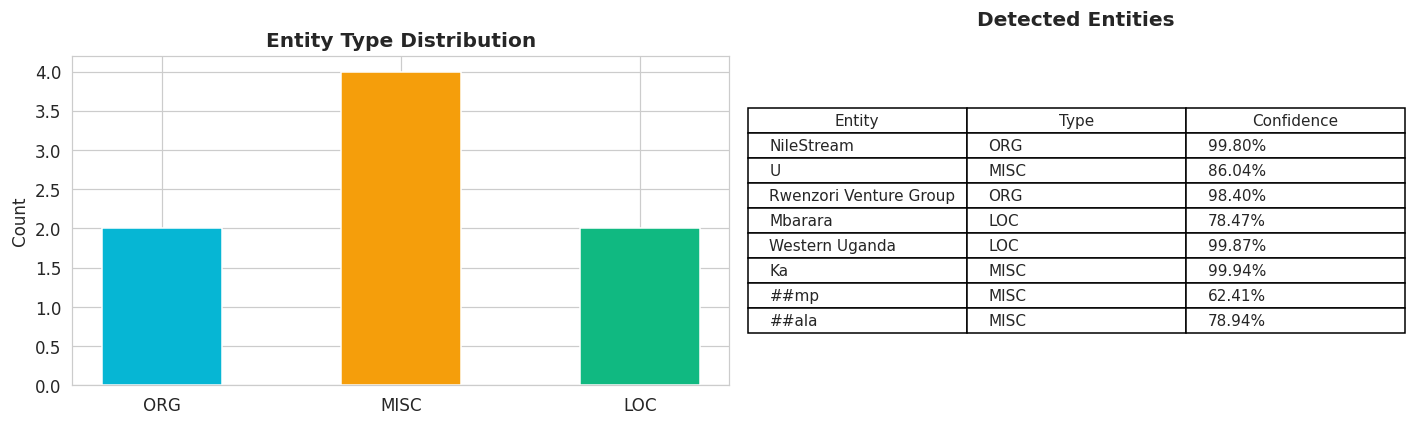

In [ ]:
# ── Transformer NER with aggregation ──────────────────────────────────────

ner_pipeline = pipeline(
    'ner',
    model='dslim/bert-base-NER',
    aggregation_strategy='simple',   # Merges sub-tokens into full entity spans
)

results = ner_pipeline(article)

entity_counts = Counter(r['entity_group'] for r in results)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

# Left: entity type distribution
colors_map = {'PER':'#A855F7','ORG':'#06B6D4','LOC':'#10B981','MISC':'#F59E0B'}
labels_list = list(entity_counts.keys())
counts_list = list(entity_counts.values())
bar_colors  = [colors_map.get(l, '#94A3B8') for l in labels_list]
ax1.bar(labels_list, counts_list, color=bar_colors, edgecolor='white', width=0.5)
ax1.set_title('Entity Type Distribution', fontweight='bold')
ax1.set_ylabel('Count')

# Right: entity list
ax2.axis('off')
table_data = [[r['word'], r['entity_group'], f"{r['score']:.2%}"] for r in results]
tbl = ax2.table(
    cellText=table_data,
    colLabels=['Entity', 'Type', 'Confidence'],
    cellLoc='left', loc='center'
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.4)
ax2.set_title('Detected Entities', fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

---
<a id='8'></a>
## 8 · Evaluation Metrics

Accuracy is often misleading — especially with **imbalanced classes** (e.g. 95% of emails are not spam).

| Metric | Formula | Use when |
|--------|---------|----------|
| **Precision** | TP / (TP + FP) | False alarms are costly (spam filters) |
| **Recall** | TP / (TP + FN) | Missing cases is costly (disease detection) |
| **F1** | 2·P·R / (P+R) | Classes are imbalanced |
| **ROC-AUC** | Area under ROC curve | Overall discriminative power |

**Tuning the decision threshold can improve F1 significantly on imbalanced data!**


---
## 🎉 You've completed the NLP Tutorial Notebook!

### What you built:
| Module | Skill |
|--------|-------|
| Preprocessing | Regex cleaning, spaCy tokenisation, lemmatisation |
| Tokenisation | Word vs BPE vs character comparison |
| TF-IDF | Vectorisation + Logistic Regression pipeline |
| Embeddings | BERT embeddings + PCA 2D semantic map |
| Attention | Heatmap from real BERT weights |
| Fine-Tuning | DistilBERT classifier with 🤗 Trainer |
| NER | spaCy + transformer NER with visualisation |
| Evaluation | PR curves, ROC-AUC, threshold tuning |

### Recommended next steps:
- [HuggingFace Hub](https://huggingface.co/models) — explore 500k+ models
- [Attention is All You Need](https://arxiv.org/abs/1706.03762) — original Transformer paper
- Try the [GLUE benchmark](https://gluebenchmark.com/) to compare your models
- Deploy your model with [HuggingFace Inference Endpoints](https://huggingface.co/inference-endpoints)
- FastAPI serving
